# PROJECT TITLE - Uncovering Banking Fraud Patterns: An Exploratory Data Analysis

## Project Goal

This project focuses on:

- Cleaning and preparing the banking transaction dataset for analysis.
- Performing Exploratory Data Analysis (EDA) to identify patterns and trends.
- Analysing the distribution of fraudulent and non-fraudulent transactions.
- Examining transaction amounts, account balances, failed transaction counts and risk scores.
- Comparing fraud rates across locations, transaction types and card-age groups.
- Investigating monthly transaction trends throughout 2023.
- Identifying relationships between numerical variables using correlation analysis.
- Creating visualizations using Matplotlib, Seaborn and Plotly.
- Developing insights and practical recommendations based on the findings.

## Dataset Columns

- **Transaction Information:** `Transaction_ID`, `User_ID`, `Timestamp`, `Transaction_Amount`
- **Account and Activity Information:** `Account_Balance`, `Daily_Transaction_Count`, `Avg_Transaction_Amount_7d`, `Failed_Transaction_Count_7d`, `Card_Age`
- **Transaction Context:** `Transaction_Type`, `Transaction_Distance`, `Device_Type`, `Location`, `Merchant_Category`, `Card_Type`, `Authentication_Method`
- **Fraud and Security Indicators:** `Risk_Score`, `IP_Address_Flag`, `Previous_Fraudulent_Activity`, `Is_Weekend`, `Fraud_Label`

**Target Variable:** `Fraud_Label`, where `0` represents a non-fraudulent transaction and `1` represents a fraudulent transaction.

## Dataset Information

| Attribute | Value |
|---|---|
| **Project Title** | Fraud Detection Transactions Analysis |
| **Source** | [Kaggle – Fraud Detection Transactions Dataset](https://www.kaggle.com/datasets/samayashar/fraud-detection-transactions-dataset) |
| **Original Records** | 50,000 rows |
| **Original Features** | 21 columns |
| **Cleaned Records** | 50,000 rows |
| **Dataset Type** | Financial transaction data |
| **Analysis Focus** | Fraud patterns, transaction characteristics, risk scores, and relationships between transaction variables |

## Features List

- **Data loading and cleaning:** Checking missing values, duplicates, data types, inconsistent categories and invalid values.
- **Data validation:** Checking binary columns and validating numerical ranges.
- **Statistical analysis:** Calculating summary statistics, including mean, median, minimum and maximum values.
- **Fraud distribution analysis:** Comparing the number and percentage of fraudulent and non-fraudulent transactions.
- **Transaction analysis:** Exploring transaction amount distributions and failed transaction counts.
- **Risk analysis:** Comparing risk scores and fraud rates across risk categories.
- **Category-based analysis:** Examining fraud rates across locations, transaction types and card-age groups.
- **Time-based analysis:** Investigating monthly transaction volume throughout 2023.
- **Correlation analysis:** Examining linear relationships between numerical variables and the fraud label.
- **Data visualization:** Creating charts with Matplotlib, Seaborn and Plotly.
- **Business insights:** Identifying notable patterns, limitations and potential areas for further investigation.

In [1]:

import pandas as pd
import numpy as np


In [2]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [3]:
df = pd.read_csv('/content/drive/MyDrive/Capstone Project/Capstone Project Dataset.csv')

In [4]:
df.head()

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Timestamp,Account_Balance,Device_Type,Location,Merchant_Category,IP_Address_Flag,...,Daily_Transaction_Count,Avg_Transaction_Amount_7d,Failed_Transaction_Count_7d,Card_Type,Card_Age,Transaction_Distance,Authentication_Method,Risk_Score,Is_Weekend,Fraud_Label
0,TXN_33553,USER_1834,39.79,POS,8/14/2023 19:30,93213.17,Laptop,Sydney,Travel,0,...,7.0,437.63,3,Amex,65,883.17,Biometric,0.8494,0,0
1,TXN_9427,USER_7875,1.19,Bank Transfer,6/7/2023 4:01,75725.25,Mobile,New York,Clothing,0,...,13.0,478.76,4,Mastercard,186,2203.36,Password,0.0959,0,1
2,TXN_199,USER_2734,28.96,Online,6/20/2023 15:25,1588.96,Tablet,Mumbai,Restaurants,0,...,14.0,50.01,4,Visa,226,1909.29,Biometric,0.8400,0,1
3,TXN_12447,USER_2617,254.32,ATM Withdrawal,12/7/2023 0:31,76807.20,Tablet,New York,Clothing,0,...,8.0,182.48,4,Visa,76,1311.86,OTP,0.7935,0,1
4,TXN_39489,USER_2014,31.28,POS,11/11/2023 23:44,92354.66,Mobile,Mumbai,Electronics,0,...,14.0,328.69,4,Mastercard,140,966.98,Password,0.3819,1,1


In [5]:
print("Dataset shape:", df.shape)

Dataset shape: (50000, 21)


In [6]:
df.columns

Index(['Transaction_ID', 'User_ID', 'Transaction_Amount', 'Transaction_Type',
       'Timestamp', 'Account_Balance', 'Device_Type', 'Location',
       'Merchant_Category', 'IP_Address_Flag', 'Previous_Fraudulent_Activity',
       'Daily_Transaction_Count', 'Avg_Transaction_Amount_7d',
       'Failed_Transaction_Count_7d', 'Card_Type', 'Card_Age',
       'Transaction_Distance', 'Authentication_Method', 'Risk_Score',
       'Is_Weekend', 'Fraud_Label'],
      dtype='object')

In [7]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Transaction_ID                50000 non-null  object 
 1   User_ID                       50000 non-null  object 
 2   Transaction_Amount            49919 non-null  float64
 3   Transaction_Type              50000 non-null  object 
 4   Timestamp                     50000 non-null  object 
 5   Account_Balance               50000 non-null  float64
 6   Device_Type                   49940 non-null  object 
 7   Location                      50000 non-null  object 
 8   Merchant_Category             50000 non-null  object 
 9   IP_Address_Flag               50000 non-null  int64  
 10  Previous_Fraudulent_Activity  50000 non-null  int64  
 11  Daily_Transaction_Count       49970 non-null  float64
 12  Avg_Transaction_Amount_7d     50000 non-null  float64
 13  F

Identifying Missing values


In [8]:

missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values("Missing_Count", ascending=False)

print(missing_summary)


                         Missing_Count  Missing_Percentage
Transaction_Amount                  81               0.162
Device_Type                         60               0.120
Daily_Transaction_Count             30               0.060
Card_Type                           30               0.060


In [9]:

# Display records with at least one missing value
missing_rows = df[df.isnull().any(axis=1)]

print("Rows containing missing values:", len(missing_rows))
display(missing_rows.head(10))


Rows containing missing values: 200


,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Timestamp,Account_Balance,Device_Type,Location,Merchant_Category,IP_Address_Flag,...,Daily_Transaction_Count,Avg_Transaction_Amount_7d,Failed_Transaction_Count_7d,Card_Type,Card_Age,Transaction_Distance,Authentication_Method,Risk_Score,Is_Weekend,Fraud_Label
18,TXN_12609,USER_5861,NaN,POS,8/16/2023 10:01,62359.52,Tablet,Tokyo,Groceries,0,...,4.0,491.21,4,Visa,29,2159.31,Password,0.4440,1,1
114,TXN_47149,USER_5937,NaN,ATM Withdrawal,9/9/2023 10:02,41767.46,NaN,Sydney,Groceries,0,...,14.0,228.01,0,Mastercard,92,4570.28,OTP,0.3784,0,0
198,TXN_20933,USER_6545,NaN,POS,10/29/2023 23:31,9674.18,Tablet,Tokyo,Travel,0,...,10.0,271.40,4,Amex,55,4345.67,OTP,0.1238,0,1
337,TXN_21779,USER_4677,NaN,Online,2/19/2023 0:29,33833.11,Laptop,Sydney,Clothing,0,...,2.0,292.32,4,Discover,116,1705.22,Biometric,0.6837,0,1
365,TXN_43514,USER_8015,131.47,ATM Withdrawal,2/7/2023 14:27,96436.96,Laptop,New York,Clothing,0,...,NaN,296.85,4,Amex,150,180.31,OTP,0.4587,0,1
457,TXN_21374,USER_2848,NaN,POS,7/16/2023 0:11,56569.67,Laptop,New York,Travel,0,...,3.0,266.76,4,Mastercard,237,3989.55,Password,0.3708,1,1
553,TXN_24155,USER_1617,NaN,Online,2/13/2023 14:01,63381.34,Tablet,New York,Travel,0,...,2.0,422.71,4,Discover,50,2311.19,OTP,0.9556,0,1
618,TXN_49598,USER_3843,NaN,Bank Transfer,8/9/2023 20:29,56038.55,Laptop,London,Groceries,0,...,14.0,374.63,4,Mastercard,140,3643.18,Password,0.9436,0,1
691,TXN_25674,USER_8317,7.49,Bank Transfer,7/17/2023 11:34,39129.50,NaN,New York,Clothing,0,...,5.0,416.51,3,Mastercard,105,2486.11,PIN,0.3196,1,0
727,TXN_3003,USER_6223,NaN,Online,7/1/2023 11:08,88980.25,Laptop,Mumbai,Electronics,0,...,8.0,458.77,2,Amex,200,3409.96,OTP,0.7266,1,0


In [10]:

print("Exact duplicate rows:", df.duplicated().sum())

print(
    "Duplicate Transaction_ID values:",
    df["Transaction_ID"].duplicated().sum()
)

print("Missing transaction IDs:", df["Transaction_ID"].isnull().sum())


Exact duplicate rows: 0
Duplicate Transaction_ID values: 0
Missing transaction IDs: 0


In [11]:

print(df["Timestamp"].head(10).to_string(index=False))

print("\nTimestamp examples:")
print(df["Timestamp"].sample(10, random_state=42).to_string(index=False))

print("\nUnique values in binary columns:")
for col in [
    "IP_Address_Flag",
    "Previous_Fraudulent_Activity",
    "Is_Weekend",
    "Fraud_Label"
]:
    print(col, sorted(df[col].dropna().unique()))


 8/14/2023 19:30
   6/7/2023 4:01
 6/20/2023 15:25
  12/7/2023 0:31
11/11/2023 23:44
  6/5/2023 20:55
  11/7/2023 1:18
  2/25/2023 3:43
  3/9/2023 22:51
 9/20/2023 17:27

Timestamp examples:
 2/10/2023 2:49
3/26/2023 22:32
 8/5/2023 12:29
1/22/2023 19:26
8/20/2023 12:11
  3/6/2023 8:36
 5/13/2023 6:40
1/22/2023 12:02
 3/26/2023 7:25
12/18/2023 7:58

Unique values in binary columns:
IP_Address_Flag [np.int64(0), np.int64(1)]
Previous_Fraudulent_Activity [np.int64(0), np.int64(1)]
Is_Weekend [np.int64(0), np.int64(1)]
Fraud_Label [np.int64(0), np.int64(1)]


Handling Missing Values

In [12]:

# Record which values are missing before imputation
missing_flags = df[
    [
        "Transaction_Amount",
        "Device_Type",
        "Daily_Transaction_Count",
        "Card_Type"
    ]
].isna()

print("Missing values before cleaning:")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nMissing cells by column:")
print(missing_flags.sum())


Missing values before cleaning:
Transaction_Amount         81
Device_Type                60
Daily_Transaction_Count    30
Card_Type                  30
dtype: int64

Missing cells by column:
Transaction_Amount         81
Device_Type                60
Daily_Transaction_Count    30
Card_Type                  30
dtype: int64


In [13]:

# Calculate medians using the available values
transaction_median = df["Transaction_Amount"].median()
daily_count_median = df["Daily_Transaction_Count"].median()

print("Transaction amount median:", transaction_median)
print("Daily transaction count median:", daily_count_median)

# Fill missing values
df["Transaction_Amount"] = (
    df["Transaction_Amount"].fillna(transaction_median)
)

df["Daily_Transaction_Count"] = (
    df["Daily_Transaction_Count"].fillna(
        round(daily_count_median)
    )
)

# Daily transaction count should be an integer count
df["Daily_Transaction_Count"] = (
    df["Daily_Transaction_Count"].astype("int64")
)


Transaction amount median: 69.61
Daily transaction count median: 7.0


In [14]:

df["Device_Type"] = df["Device_Type"].fillna("Unknown")
df["Card_Type"] = df["Card_Type"].fillna("Unknown")

print("Missing values after imputation:")
print(df.isna().sum()[df.isna().sum() > 0])


Missing values after imputation:
Series([], dtype: int64)


In [15]:

print("Dataset shape:", df.shape)

print("\nMissing values in all columns:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nBinary column validation:")
binary_columns = [
    "IP_Address_Flag",
    "Previous_Fraudulent_Activity",
    "Is_Weekend",
    "Fraud_Label"
]

for col in binary_columns:
    print(col, sorted(df[col].dropna().unique()))

print("\nData types after cleaning:")
print(df.dtypes)


Dataset shape: (50000, 21)

Missing values in all columns:
Transaction_ID                  0
User_ID                         0
Transaction_Amount              0
Transaction_Type                0
Timestamp                       0
Account_Balance                 0
Device_Type                     0
Location                        0
Merchant_Category               0
IP_Address_Flag                 0
Previous_Fraudulent_Activity    0
Daily_Transaction_Count         0
Avg_Transaction_Amount_7d       0
Failed_Transaction_Count_7d     0
Card_Type                       0
Card_Age                        0
Transaction_Distance            0
Authentication_Method           0
Risk_Score                      0
Is_Weekend                      0
Fraud_Label                     0
dtype: int64

Duplicate rows: 0

Binary column validation:
IP_Address_Flag [np.int64(0), np.int64(1)]
Previous_Fraudulent_Activity [np.int64(0), np.int64(1)]
Is_Weekend [np.int64(0), np.int64(1)]
Fraud_Label [np.int64(0), np.in

Check for invalid values

In [16]:

columns = [
    "Transaction_Amount",
    "Account_Balance",
    "Daily_Transaction_Count",
    "Avg_Transaction_Amount_7d",
    "Failed_Transaction_Count_7d",
    "Card_Age",
    "Transaction_Distance",
    "Risk_Score"
]

for col in columns:
    print("\nColumn:", col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Standard Deviation:", df[col].std())



Column: Transaction_Amount
Mean: 99.3083742
Median: 69.61
Standard Deviation: 98.56550848821347

Column: Account_Balance
Mean: 50294.065980800005
Median: 50384.43
Standard Deviation: 28760.458557251746

Column: Daily_Transaction_Count
Mean: 7.48252
Median: 7.0
Standard Deviation: 4.038021862498394

Column: Avg_Transaction_Amount_7d
Mean: 255.2719244
Median: 256.085
Standard Deviation: 141.3822793696256

Column: Failed_Transaction_Count_7d
Mean: 2.00354
Median: 2.0
Standard Deviation: 1.4142727713385208

Column: Card_Age
Mean: 119.99994
Median: 120.0
Standard Deviation: 68.9858173892026

Column: Transaction_Distance
Mean: 2499.1641554
Median: 2490.785
Standard Deviation: 1442.0138335532895

Column: Risk_Score
Mean: 0.501555518
Median: 0.50225
Standard Deviation: 0.28777411902536226


In [17]:

# Check transaction amounts
invalid_amounts = df[
    df["Transaction_Amount"] < 0
]
print("Negative transaction amounts:", len(invalid_amounts))

# Check transaction counts
invalid_counts = df[
    (df["Daily_Transaction_Count"] < 0) |
    (df["Failed_Transaction_Count_7d"] < 0)
]
print("Negative transaction counts:", len(invalid_counts))

# Check risk scores
invalid_risk = df[
    (df["Risk_Score"] < 0) |
    (df["Risk_Score"] > 1)
]
print("Risk scores outside 0–1:", len(invalid_risk))


Negative transaction amounts: 0
Negative transaction counts: 0
Risk scores outside 0–1: 0


In [18]:

if len(invalid_amounts) > 0:
    print("Investigate negative transaction amounts.")
else:
    print("No negative transaction amounts found.")


No negative transaction amounts found.


In [19]:

Q1 = df["Transaction_Amount"].quantile(0.25)
Q3 = df["Transaction_Amount"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

outliers = df[
    (df["Transaction_Amount"] < lower_limit) |
    (df["Transaction_Amount"] > upper_limit)
]

print("Potential outliers:", len(outliers))


Q1: 28.71
Q3: 138.5825
IQR: 109.8725
Lower limit: -136.09875
Upper limit: 303.39125
Potential outliers: 2268


Investigate the outliers

In [20]:

# Display the 10 largest transaction amounts
display(
    df[["Transaction_Amount"]]
    .sort_values(
        by="Transaction_Amount",
        ascending=False
    )
    .head(10)
)

# Check the range of the potential outliers
print("Smallest outlier:", outliers["Transaction_Amount"].min())
print("Largest outlier:", outliers["Transaction_Amount"].max())


,Transaction_Amount
45306,1174.14
47457,1005.32
31360,971.61
37280,898.80
33925,892.67
28983,886.30
5448,875.71
35377,874.85
7583,868.75
7199,864.36


Smallest outlier: 303.43
Largest outlier: 1174.14


In [21]:

columns_to_check = [
    "Transaction_Amount",
    "Account_Balance",
    "Avg_Transaction_Amount_7d",
    "Transaction_Distance"
]

for col in columns_to_check:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_count = len(
        df[
            (df[col] < lower) |
            (df[col] > upper)
        ]
    )

    print("\nColumn:", col)
    print("Lower fence:", round(lower, 2))
    print("Upper fence:", round(upper, 2))
    print("Potential outliers:", outlier_count)



Column: Transaction_Amount
Lower fence: -136.1
Upper fence: 303.39
Potential outliers: 2268

Column: Account_Balance
Lower fence: -49282.72
Upper fence: 149753.85
Potential outliers: 0

Column: Avg_Transaction_Amount_7d
Lower fence: -236.83
Upper fence: 746.95
Potential outliers: 0

Column: Transaction_Distance
Lower fence: -2478.35
Upper fence: 7481.24
Potential outliers: 0


Check inconsistent categorical values

In [22]:

categorical_columns = [
    "Transaction_Type",
    "Device_Type",
    "Location",
    "Merchant_Category",
    "Card_Type",
    "Authentication_Method"
]

for col in categorical_columns:
    print("\nColumn:", col)
    print(df[col].value_counts(dropna=False).to_string())



Column: Transaction_Type
Transaction_Type
POS               12549
Online            12546
ATM Withdrawal    12453
Bank Transfer     12452

Column: Device_Type
Device_Type
Tablet     16762
Mobile     16624
Laptop     16554
Unknown       60

Column: Location
Location
Tokyo       10208
Mumbai       9994
London       9945
Sydney       9938
New York     9915

Column: Merchant_Category
Merchant_Category
Clothing       10033
Groceries      10019
Travel         10015
Restaurants     9976
Electronics     9957

Column: Card_Type
Card_Type
Mastercard    12681
Visa          12554
Amex          12415
Discover      12320
Unknown          30

Column: Authentication_Method
Authentication_Method
Biometric    12591
PIN          12586
Password     12457
OTP          12366


In [23]:

for col in categorical_columns:
    text_values = df[col].dropna().astype(str)

    spaces = text_values[
        text_values != text_values.str.strip()
    ]

    print(col, "- values with extra spaces:", len(spaces))


Transaction_Type - values with extra spaces: 0
Device_Type - values with extra spaces: 0
Location - values with extra spaces: 0
Merchant_Category - values with extra spaces: 0
Card_Type - values with extra spaces: 0
Authentication_Method - values with extra spaces: 0


Check numerical ranges

In [24]:

print("Transaction Amount range:",
      df["Transaction_Amount"].min(),
      "to",
      df["Transaction_Amount"].max())

print("Account Balance range:",
      df["Account_Balance"].min(),
      "to",
      df["Account_Balance"].max())

print("Card Age range:",
      df["Card_Age"].min(),
      "to",
      df["Card_Age"].max())

print("Transaction Distance range:",
      df["Transaction_Distance"].min(),
      "to",
      df["Transaction_Distance"].max())


Transaction Amount range: 0.0 to 1174.14
Account Balance range: 500.48 to 99998.31
Card Age range: 1 to 239
Transaction Distance range: 0.25 to 4999.93


In [25]:

print("Daily Transaction Count:")
print("Minimum:", df["Daily_Transaction_Count"].min())
print("Maximum:", df["Daily_Transaction_Count"].max())

print("\nFailed Transaction Count:")
print("Minimum:", df["Failed_Transaction_Count_7d"].min())
print("Maximum:", df["Failed_Transaction_Count_7d"].max())


Daily Transaction Count:
Minimum: 1
Maximum: 14

Failed Transaction Count:
Minimum: 0
Maximum: 4


In [26]:

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Fraud label values:",
      sorted(df["Fraud_Label"].unique()))


Rows: 50000
Columns: 21
Missing values: 0
Duplicate rows: 0
Fraud label values: [np.int64(0), np.int64(1)]


In [27]:

zero_transactions = df[df["Transaction_Amount"] == 0]

print("Zero-amount transactions:", len(zero_transactions))

display(zero_transactions.head(10))


Zero-amount transactions: 2


,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Timestamp,Account_Balance,Device_Type,Location,Merchant_Category,IP_Address_Flag,...,Daily_Transaction_Count,Avg_Transaction_Amount_7d,Failed_Transaction_Count_7d,Card_Type,Card_Age,Transaction_Distance,Authentication_Method,Risk_Score,Is_Weekend,Fraud_Label
9775,TXN_12945,USER_8426,0.0,POS,8/1/2023 18:07,92945.09,Tablet,London,Electronics,0,...,13,396.37,2,Discover,209,3073.23,Biometric,0.9289,0,1
17233,TXN_10863,USER_8798,0.0,POS,2/16/2023 4:17,79882.97,Mobile,Tokyo,Restaurants,0,...,14,329.63,0,Discover,230,4158.76,Password,0.9429,0,1


In [28]:

display(
    df.loc[
        df["Transaction_Amount"] == 0,
        [
            "Transaction_ID",
            "Transaction_Amount",
            "Transaction_Type",
            "Account_Balance",
            "Daily_Transaction_Count",
            "Avg_Transaction_Amount_7d",
            "Risk_Score",
            "Fraud_Label"
        ]
    ]
)


,Transaction_ID,Transaction_Amount,Transaction_Type,Account_Balance,Daily_Transaction_Count,Avg_Transaction_Amount_7d,Risk_Score,Fraud_Label
9775,TXN_12945,0.0,POS,92945.09,13,396.37,0.9289,1
17233,TXN_10863,0.0,POS,79882.97,14,329.63,0.9429,1


In [29]:

# Document the zero-amount transaction check
zero_transactions = df[df["Transaction_Amount"] == 0]

print("Zero-amount transactions:", len(zero_transactions))
print("Decision: Retained pending dataset definition.")


Zero-amount transactions: 2
Decision: Retained pending dataset definition.


Two zero-amount transactions were identified during data validation. Both were present in the original dataset and were retained pending confirmation of whether zero-value transactions are permitted by the dataset's definition.

In [30]:

print(
    "Non-whole daily counts:",
    (df["Daily_Transaction_Count"] % 1 != 0).sum()
)

print(
    "Non-whole failed transaction counts:",
    (df["Failed_Transaction_Count_7d"] % 1 != 0).sum()
)


Non-whole daily counts: 0
Non-whole failed transaction counts: 0


In [31]:

import os

print("Saved file location:", os.path.abspath("Capstone_Cleaned_Dataset.csv"))
print("File exists:", os.path.exists("Capstone_Cleaned_Dataset.csv"))


Saved file location: /content/Capstone_Cleaned_Dataset.csv
File exists: False


In [32]:

# Save the cleaned dataset
df.to_csv("Capstone_Cleaned_Dataset.csv", index=False)

# Download the file to your computer
from google.colab import files
files.download("Capstone_Cleaned_Dataset.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Add Timestamp Conversion

In [33]:

# Convert and validate timestamps
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

print(
    "Invalid or missing timestamps:",
    df["Timestamp"].isna().sum()
)


Invalid or missing timestamps: 0


Stamdardize categorical values

In [34]:

categorical_columns = [
    "Transaction_Type",
    "Device_Type",
    "Location",
    "Merchant_Category",
    "Card_Type",
    "Authentication_Method"
]

for col in categorical_columns:
    df[col] = df[col].astype("string").str.strip()

print("Categorical values standardised.")


Categorical values standardised.


Validate binary columns

In [35]:

binary_columns = [
    "IP_Address_Flag",
    "Previous_Fraudulent_Activity",
    "Is_Weekend",
    "Fraud_Label"
]

for col in binary_columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))



IP_Address_Flag
IP_Address_Flag
0    47490
1     2510
Name: count, dtype: int64

Previous_Fraudulent_Activity
Previous_Fraudulent_Activity
0    45080
1     4920
Name: count, dtype: int64

Is_Weekend
Is_Weekend
0    35018
1    14982
Name: count, dtype: int64

Fraud_Label
Fraud_Label
0    33933
1    16067
Name: count, dtype: int64


In [36]:

for col in binary_columns:
    invalid = df[~df[col].isin([0, 1])]
    print(col, "- invalid binary values:", len(invalid))


IP_Address_Flag - invalid binary values: 0
Previous_Fraudulent_Activity - invalid binary values: 0
Is_Weekend - invalid binary values: 0
Fraud_Label - invalid binary values: 0


Add the numerical range validation

In [37]:

validation_columns = [
    "Account_Balance",
    "Failed_Transaction_Count_7d",
    "Card_Age",
    "Transaction_Distance",
    "Risk_Score"
]

for col in validation_columns:
    print(f"\n{col}")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Missing:", df[col].isna().sum())



Account_Balance
Minimum: 500.48
Maximum: 99998.31
Missing: 0

Failed_Transaction_Count_7d
Minimum: 0
Maximum: 4
Missing: 0

Card_Age
Minimum: 1
Maximum: 239
Missing: 0

Transaction_Distance
Minimum: 0.25
Maximum: 4999.93
Missing: 0

Risk_Score
Minimum: 0.0001
Maximum: 1.0
Missing: 0


In [38]:

df.to_csv("Capstone_Cleaned_Dataset.csv", index=False)


#EXPLORATORY DATA ANALYSIS

Objective of EDA

Exploratory Data Analysis was conducted to understand the structure, distribution and characteristics of the Banking Fraud Detection and Risk Analytics dataset before creating visualisations and drawing conclusions.

The analysis aims to summarise numerical variables using descriptive statistics, identify the most frequent categories, examine the distribution of fraud and non-fraud transactions, and investigate how transaction and account characteristics vary across fraud labels.

The analysis focuses on identifying patterns and relationships that may help explain transaction risk. These patterns are exploratory and do not, by themselves, establish causation.

The EDA is designed to answer the following questions:

What types of variables are present in the dataset, and how are their values distributed?

What proportion of transactions are labelled fraudulent?

How does the fraud rate vary across transaction types, locations, device types and card types?

Does card age show a relationship with the observed fraud rate?

How do transaction amounts, failed transaction counts and risk scores differ between fraudulent and non-fraudulent transactions?

Which numerical variables show stronger relationships with one another?




The dataset has 21 columns. Based on their names and the values you've shown, we can classify them as follows.

***Identifiers*** -
Transaction_ID
User_ID

***Numerical measurements*** -
Transaction_Amount
Account_Balance
Avg_Transaction_Amount_7d
Transaction_Distance
Risk_Score

***Numerical counts*** -
Daily_Transaction_Count
Failed_Transaction_Count_7d

***Numerical age*** -
Card_Age

***Categorical*** -
Transaction_Type
Device_Type
Location
Merchant_Category
Card_Type
Authentication_Method

***Binary*** -
IP_Address_Flag
Previous_Fraudulent_Activity
Is_Weekend
Fraud_Label

***Date and Time*** -
Timestamp






In [39]:

# Create a summary of all columns and their data types
column_summary = pd.DataFrame({
    "Column_Name": df.columns,
    "Data_Type": df.dtypes.astype(str).values
})

display(column_summary)


,Column_Name,Data_Type
0,Transaction_ID,object
1,User_ID,object
2,Transaction_Amount,float64
3,Transaction_Type,string
4,Timestamp,datetime64[ns]
5,Account_Balance,float64
6,Device_Type,string
7,Location,string
8,Merchant_Category,string
9,IP_Address_Flag,int64


In [40]:

# Analyze numerical data

# Transaction Amount
print("TRANSACTION AMOUNT")
print("Mean:", df["Transaction_Amount"].mean())
print("Median:", df["Transaction_Amount"].median())
print("Minimum:", df["Transaction_Amount"].min())
print("Maximum:", df["Transaction_Amount"].max())
print("Standard Deviation:", df["Transaction_Amount"].std())

# Account Balance
print("\nACCOUNT BALANCE")
print("Mean:", df["Account_Balance"].mean())
print("Median:", df["Account_Balance"].median())
print("Minimum:", df["Account_Balance"].min())
print("Maximum:", df["Account_Balance"].max())
print("Standard Deviation:", df["Account_Balance"].std())

# Daily Transaction Count
print("\nDAILY TRANSACTION COUNT")
print("Mean:", df["Daily_Transaction_Count"].mean())
print("Median:", df["Daily_Transaction_Count"].median())
print("Minimum:", df["Daily_Transaction_Count"].min())
print("Maximum:", df["Daily_Transaction_Count"].max())
print("Standard Deviation:", df["Daily_Transaction_Count"].std())

# Average Transaction Amount in 7 Days
print("\nAVERAGE TRANSACTION AMOUNT (7 DAYS)")
print("Mean:", df["Avg_Transaction_Amount_7d"].mean())
print("Median:", df["Avg_Transaction_Amount_7d"].median())
print("Minimum:", df["Avg_Transaction_Amount_7d"].min())
print("Maximum:", df["Avg_Transaction_Amount_7d"].max())
print("Standard Deviation:", df["Avg_Transaction_Amount_7d"].std())

# Failed Transaction Count in 7 Days
print("\nFAILED TRANSACTION COUNT (7 DAYS)")
print("Mean:", df["Failed_Transaction_Count_7d"].mean())
print("Median:", df["Failed_Transaction_Count_7d"].median())
print("Minimum:", df["Failed_Transaction_Count_7d"].min())
print("Maximum:", df["Failed_Transaction_Count_7d"].max())
print("Standard Deviation:", df["Failed_Transaction_Count_7d"].std())

# Card Age
print("\nCARD AGE")
print("Mean:", df["Card_Age"].mean())
print("Median:", df["Card_Age"].median())
print("Minimum:", df["Card_Age"].min())
print("Maximum:", df["Card_Age"].max())
print("Standard Deviation:", df["Card_Age"].std())

# Transaction Distance
print("\nTRANSACTION DISTANCE")
print("Mean:", df["Transaction_Distance"].mean())
print("Median:", df["Transaction_Distance"].median())
print("Minimum:", df["Transaction_Distance"].min())
print("Maximum:", df["Transaction_Distance"].max())
print("Standard Deviation:", df["Transaction_Distance"].std())

# Risk Score
print("\nRISK SCORE")
print("Mean:", df["Risk_Score"].mean())
print("Median:", df["Risk_Score"].median())
print("Minimum:", df["Risk_Score"].min())
print("Maximum:", df["Risk_Score"].max())
print("Standard Deviation:", df["Risk_Score"].std())


TRANSACTION AMOUNT
Mean: 99.3083742
Median: 69.61
Minimum: 0.0
Maximum: 1174.14
Standard Deviation: 98.56550848821347

ACCOUNT BALANCE
Mean: 50294.065980800005
Median: 50384.43
Minimum: 500.48
Maximum: 99998.31
Standard Deviation: 28760.458557251746

DAILY TRANSACTION COUNT
Mean: 7.48252
Median: 7.0
Minimum: 1
Maximum: 14
Standard Deviation: 4.038021862498394

AVERAGE TRANSACTION AMOUNT (7 DAYS)
Mean: 255.2719244
Median: 256.085
Minimum: 10.0
Maximum: 500.0
Standard Deviation: 141.3822793696256

FAILED TRANSACTION COUNT (7 DAYS)
Mean: 2.00354
Median: 2.0
Minimum: 0
Maximum: 4
Standard Deviation: 1.4142727713385208

CARD AGE
Mean: 119.99994
Median: 120.0
Minimum: 1
Maximum: 239
Standard Deviation: 68.9858173892026

TRANSACTION DISTANCE
Mean: 2499.1641554
Median: 2490.785
Minimum: 0.25
Maximum: 4999.93
Standard Deviation: 1442.0138335532895

RISK SCORE
Mean: 0.501555518
Median: 0.50225
Minimum: 0.0001
Maximum: 1.0
Standard Deviation: 0.28777411902536226


In [41]:
# Analyze Categorical Data

# Transaction Type
print("TRANSACTION TYPE")
print(df["Transaction_Type"].value_counts())
print("Most common:", df["Transaction_Type"].mode()[0])

# Device Type
print("\nDEVICE TYPE")
print(df["Device_Type"].value_counts())
print("Most common:", df["Device_Type"].mode()[0])

# Location
print("\nLOCATION")
print(df["Location"].value_counts())
print("Most common:", df["Location"].mode()[0])

# Merchant Category
print("\nMERCHANT CATEGORY")
print(df["Merchant_Category"].value_counts())
print("Most common:", df["Merchant_Category"].mode()[0])

# Card Type
print("\nCARD TYPE")
print(df["Card_Type"].value_counts())
print("Most common:", df["Card_Type"].mode()[0])

# Authentication Method
print("\nAUTHENTICATION METHOD")
print(df["Authentication_Method"].value_counts())
print("Most common:", df["Authentication_Method"].mode()[0])


TRANSACTION TYPE
Transaction_Type
POS               12549
Online            12546
ATM Withdrawal    12453
Bank Transfer     12452
Name: count, dtype: Int64
Most common: POS

DEVICE TYPE
Device_Type
Tablet     16762
Mobile     16624
Laptop     16554
Unknown       60
Name: count, dtype: Int64
Most common: Tablet

LOCATION
Location
Tokyo       10208
Mumbai       9994
London       9945
Sydney       9938
New York     9915
Name: count, dtype: Int64
Most common: Tokyo

MERCHANT CATEGORY
Merchant_Category
Clothing       10033
Groceries      10019
Travel         10015
Restaurants     9976
Electronics     9957
Name: count, dtype: Int64
Most common: Clothing

CARD TYPE
Card_Type
Mastercard    12681
Visa          12554
Amex          12415
Discover      12320
Unknown          30
Name: count, dtype: Int64
Most common: Mastercard

AUTHENTICATION METHOD
Authentication_Method
Biometric    12591
PIN          12586
Password     12457
OTP          12366
Name: count, dtype: Int64
Most common: Biometric


The dataset contains 50,000 transaction records and 21 columns. Initial descriptive analysis shows that the mean transaction amount is approximately 99.31, compared with a median of 69.61, suggesting a potentially right-skewed distribution. The mean risk score is approximately 0.502, and its median is approximately 0.502.

Among the categorical variables, POS is the most frequent transaction type, Tablet is the most frequent device type, Tokyo is the most frequent location, Clothing is the most frequent merchant category, Mastercard is the most frequent card type, and Biometric is the most frequent authentication method.

These initial findings describe the dataset but do not yet establish which characteristics are associated with fraud. Further grouped analysis and visualisation will be used to investigate the research questions

In [42]:

# Create an empty list
risk_categories = []

# Check each risk score
for score in df["Risk_Score"]:
    if score < 0.33:
        risk_categories.append("Low")
    elif score < 0.66:
        risk_categories.append("Medium")
    else:
        risk_categories.append("High")

# Add the categories as a new column
df["Risk_Category"] = risk_categories

print(df["Risk_Category"].value_counts())


Risk_Category
High      17010
Medium    16647
Low       16343
Name: count, dtype: int64


In [43]:
# Create card age groups


card_age_groups = []

for age in df["Card_Age"]:
    if age <= 60:
        card_age_groups.append("1-60 days")
    elif age <= 120:
        card_age_groups.append("61-120 days")
    elif age <= 180:
        card_age_groups.append("121-180 days")
    else:
        card_age_groups.append("181-239 days")

df["Card_Age_Group"] = card_age_groups

print(df["Card_Age_Group"].value_counts())


Card_Age_Group
121-180 days    12569
1-60 days       12566
61-120 days     12542
181-239 days    12323
Name: count, dtype: int64


We'll use value_counts() to count transactions in each category and simple for loops with if conditions to calculate the fraud rates.

The fraud rate for a category is:
                Fraud Rate = Fraudulent Transactions/Total Transactions *100

**1. Fraud by location**

*Are some locations associated with a higher observed fraud rate than others?*

In [44]:

print("FRAUD BY LOCATION")

for location in df["Location"].unique():
    total = 0
    fraud = 0

    for i in range(len(df)):
        if df["Location"].iloc[i] == location:
            total += 1
            if df["Fraud_Label"].iloc[i] == 1:
                fraud += 1

    print(location, "- Transactions:", total,
          "- Fraud:", fraud,
          "- Fraud rate:", round(fraud / total * 100, 2), "%")


FRAUD BY LOCATION
Sydney - Transactions: 9938 - Fraud: 3194 - Fraud rate: 32.14 %
New York - Transactions: 9915 - Fraud: 3221 - Fraud rate: 32.49 %
Mumbai - Transactions: 9994 - Fraud: 3156 - Fraud rate: 31.58 %
Tokyo - Transactions: 10208 - Fraud: 3315 - Fraud rate: 32.47 %
London - Transactions: 9945 - Fraud: 3181 - Fraud rate: 31.99 %


**2. Fraud by card type**

*Does the observed fraud rate differ between Visa, Mastercard, Amex and Discover?*

In [45]:

print("FRAUD BY CARD TYPE")

for card in df["Card_Type"].unique():
    total = 0
    fraud = 0

    for i in range(len(df)):
        if df["Card_Type"].iloc[i] == card:
            total += 1
            if df["Fraud_Label"].iloc[i] == 1:
                fraud += 1

    print(card, "- Transactions:", total,
          "- Fraud:", fraud,
          "- Fraud rate:", round(fraud / total * 100, 2), "%")



FRAUD BY CARD TYPE
Amex - Transactions: 12415 - Fraud: 4019 - Fraud rate: 32.37 %
Mastercard - Transactions: 12681 - Fraud: 4036 - Fraud rate: 31.83 %
Visa - Transactions: 12554 - Fraud: 3999 - Fraud rate: 31.85 %
Discover - Transactions: 12320 - Fraud: 4000 - Fraud rate: 32.47 %
Unknown - Transactions: 30 - Fraud: 13 - Fraud rate: 43.33 %


**3. Fraud by card age group**

*Does the observed fraud rate vary with card age?*

In [46]:

print("FRAUD BY CARD AGE GROUP")

for age_group in df["Card_Age_Group"].unique():
    total = 0
    fraud = 0

    for i in range(len(df)):
        if df["Card_Age_Group"].iloc[i] == age_group:
            total += 1
            if df["Fraud_Label"].iloc[i] == 1:
                fraud += 1

    print(age_group, "- Transactions:", total,
          "- Fraud:", fraud,
          "- Fraud rate:", round(fraud / total * 100, 2), "%")


FRAUD BY CARD AGE GROUP
61-120 days - Transactions: 12542 - Fraud: 4067 - Fraud rate: 32.43 %
181-239 days - Transactions: 12323 - Fraud: 3923 - Fraud rate: 31.83 %
121-180 days - Transactions: 12569 - Fraud: 4037 - Fraud rate: 32.12 %
1-60 days - Transactions: 12566 - Fraud: 4040 - Fraud rate: 32.15 %


**4. Fraud by risk score category**

*Does the observed fraud rate increase across low, medium and high risk scores?*

In [47]:

print("FRAUD BY RISK CATEGORY")

for category in ["Low", "Medium", "High"]:
    total = 0
    fraud = 0

    for i in range(len(df)):
        if df["Risk_Category"].iloc[i] == category:
            total += 1
            if df["Fraud_Label"].iloc[i] == 1:
                fraud += 1

    if total > 0:
        print(category, "- Transactions:", total,
              "- Fraud:", fraud,
              "- Fraud rate:", round(fraud / total * 100, 2), "%")



FRAUD BY RISK CATEGORY
Low - Transactions: 16343 - Fraud: 3266 - Fraud rate: 19.98 %
Medium - Transactions: 16647 - Fraud: 3272 - Fraud rate: 19.66 %
High - Transactions: 17010 - Fraud: 9529 - Fraud rate: 56.02 %


**5. Fraud by transaction type**

*Does the fraud rate differ between POS, online, ATM withdrawal and bank transfer transactions?*

In [48]:

print("FRAUD BY TRANSACTION TYPE")

for transaction in df["Transaction_Type"].unique():
    total = 0
    fraud = 0

    for i in range(len(df)):
        if df["Transaction_Type"].iloc[i] == transaction:
            total += 1
            if df["Fraud_Label"].iloc[i] == 1:
                fraud += 1

    print(transaction, "- Transactions:", total,
          "- Fraud:", fraud,
          "- Fraud rate:", round(fraud / total * 100, 2), "%")


FRAUD BY TRANSACTION TYPE
POS - Transactions: 12549 - Fraud: 3995 - Fraud rate: 31.84 %
Bank Transfer - Transactions: 12452 - Fraud: 3995 - Fraud rate: 32.08 %
Online - Transactions: 12546 - Fraud: 4031 - Fraud rate: 32.13 %
ATM Withdrawal - Transactions: 12453 - Fraud: 4046 - Fraud rate: 32.49 %


**6. Comparison of Account Balance by Fraud**

In [49]:

# Separate non-fraudulent transactions
non_fraud = df[df["Fraud_Label"] == 0]

# Separate fraudulent transactions
fraud = df[df["Fraud_Label"] == 1]

print("ACCOUNT BALANCE")

print("Non-fraudulent mean:",
      non_fraud["Account_Balance"].mean())

print("Fraudulent mean:",
      fraud["Account_Balance"].mean())

print("Non-fraudulent median:",
      non_fraud["Account_Balance"].median())

print("Fraudulent median:",
      fraud["Account_Balance"].median())


ACCOUNT BALANCE
Non-fraudulent mean: 50356.47285238558
Fraudulent mean: 50162.264625630174
Non-fraudulent median: 50370.35
Fraudulent median: 50415.02


The mean account balance for non-fraudulent transactions was approximately 50,356.47, compared with 50,162.26 for fraudulent transactions. The median account balance was 50,370.35 for non-fraudulent transactions and 50,415.02 for fraudulent transactions.

The difference in means was relatively small compared with the overall account balance values, while the medians showed the opposite pattern. Therefore, these descriptive statistics alone do not indicate a clear relationship between account balance and fraud status. Further analysis is required to examine the distributions and spread of balances across the two groups.

**7. Transaction Amount and Fraud Status**

In [50]:

# Transaction amount for non-fraudulent transactions
print("TRANSACTION AMOUNT")

print("Non-fraudulent mean:",
      non_fraud["Transaction_Amount"].mean())

print("Fraudulent mean:",
      fraud["Transaction_Amount"].mean())

print("Non-fraudulent median:",
      non_fraud["Transaction_Amount"].median())

print("Fraudulent median:",
      fraud["Transaction_Amount"].median())


TRANSACTION AMOUNT
Non-fraudulent mean: 99.19213007986328
Fraudulent mean: 99.5538781353084
Non-fraudulent median: 69.47
Fraudulent median: 69.84


The mean transaction amount was approximately 99.19 for non-fraudulent transactions and 99.55 for fraudulent transactions. The corresponding median values were 69.47 and 69.84.

The differences in both the mean and median were small. Therefore, the descriptive statistics do not indicate a substantial difference in central transaction amounts between fraudulent and non-fraudulent transactions. Further analysis of the distributions and relationships with other variables is needed before drawing broader conclusions.

**8. Failed transaction counts Comparison**

In [51]:

print("FAILED TRANSACTION COUNT")

print("Non-fraudulent mean:",
      non_fraud["Failed_Transaction_Count_7d"].mean())

print("Fraudulent mean:",
      fraud["Failed_Transaction_Count_7d"].mean())

print("Non-fraudulent median:",
      non_fraud["Failed_Transaction_Count_7d"].median())

print("Fraudulent median:",
      fraud["Failed_Transaction_Count_7d"].median())


FAILED TRANSACTION COUNT
Non-fraudulent mean: 1.5073527244864882
Fraudulent mean: 3.0514719611626315
Non-fraudulent median: 2.0
Fraudulent median: 4.0


The mean failed transaction count over the preceding seven days was approximately 1.51 for non-fraudulent transactions and 3.05 for fraudulent transactions. The median was 2 for non-fraudulent transactions and 4 for fraudulent transactions.

Both the mean and median were higher in the fraudulent group. This suggests a potential association between recent failed transaction activity and fraud status in the dataset. Further analysis is required to understand the strength and distribution of this relationship.

**9. Comparison Of Risk Scores by Fraud Status**

In [52]:

print("RISK SCORE")

print("Non-fraudulent mean:",
      non_fraud["Risk_Score"].mean())

print("Fraudulent mean:",
      fraud["Risk_Score"].mean())

print("Non-fraudulent median:",
      non_fraud["Risk_Score"].median())

print("Fraudulent median:",
      fraud["Risk_Score"].median())


RISK SCORE
Non-fraudulent mean: 0.4251583768013439
Fraudulent mean: 0.6629038837368519
Non-fraudulent median: 0.4263
Fraudulent median: 0.8069


The mean risk score was approximately 0.4252 for non-fraudulent transactions and 0.6629 for fraudulent transactions. The median risk score was 0.4263 for non-fraudulent transactions and 0.8069 for fraudulent transactions.

Both the mean and median were higher for fraudulent transactions, suggesting a clear association between risk score and fraud status in this dataset. This finding is consistent with the earlier comparison of low-, medium- and high-risk categories. However, the method used to calculate the risk score should be examined before concluding that it independently indicates fraud.

**10. Correlation Analysis**

Here the relationships between numerical variables are evaluated. This will help us answer questions such as:
- Is transaction amount correlated with account balance?
- Is failed transaction count correlated with risk score?
- Which numerical variables have the strongest positive or negative correlation with Fraud_Label?

In [53]:

correlation_matrix = df[
    [
        "Transaction_Amount",
        "Account_Balance",
        "Daily_Transaction_Count",
        "Avg_Transaction_Amount_7d",
        "Failed_Transaction_Count_7d",
        "Card_Age",
        "Transaction_Distance",
        "Risk_Score",
        "Fraud_Label"
    ]
].corr()

print(correlation_matrix.round(2))


                             Transaction_Amount  Account_Balance  \
Transaction_Amount                         1.00            -0.00   
Account_Balance                           -0.00             1.00   
Daily_Transaction_Count                    0.00             0.01   
Avg_Transaction_Amount_7d                 -0.01            -0.00   
Failed_Transaction_Count_7d                0.00            -0.00   
Card_Age                                   0.00             0.00   
Transaction_Distance                       0.01             0.00   
Risk_Score                                 0.01            -0.01   
Fraud_Label                                0.00            -0.00   

                             Daily_Transaction_Count  \
Transaction_Amount                              0.00   
Account_Balance                                 0.01   
Daily_Transaction_Count                         1.00   
Avg_Transaction_Amount_7d                       0.00   
Failed_Transaction_Count_7d            

# DATA VISUALIZATION

The purpose of the data visualization section is to present the findings from the cleaned Banking Fraud Detection and Risk Analytics dataset using charts and graphs. While statistical analysis helps us understand numerical summaries and relationships, visualization makes patterns, differences, and trends easier to identify and interpret.

In this section, I will use Python visualization libraries such as **Matplotlib**, **Seaborn**, and **Plotly** to explore transaction characteristics and compare fraudulent and non-fraudulent transactions. The visualizations will focus on factors such as transaction amounts, risk scores, failed transaction counts, account balances, and fraud rates across different categories.


In [54]:

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


**1. Fraud vs. Non-Fraud Distribution**

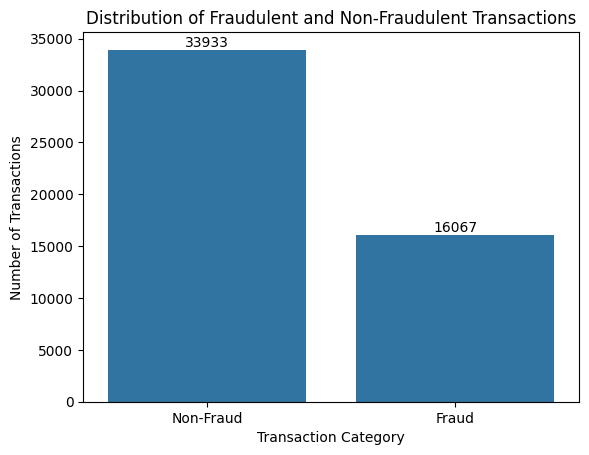

In [55]:


df["Fraud_Status"] = df["Fraud_Label"].map({
    0: "Non-Fraud",
    1: "Fraud"
})

ax = sns.countplot(data=df, x="Fraud_Status",
                   order=["Non-Fraud", "Fraud"])

plt.title("Distribution of Fraudulent and Non-Fraudulent Transactions")
plt.xlabel("Transaction Category")
plt.ylabel("Number of Transactions")

for bar in ax.patches:
    count = int(bar.get_height())
    ax.text(bar.get_x() + bar.get_width() / 2,
            count,
            str(count),
            ha="center",
            va="bottom")

plt.show()



In [56]:

transactions_below_100 = (df["Transaction_Amount"] < 100).sum()

percentage_below_100 = (
    transactions_below_100 / len(df)
) * 100

print("Transactions below 100:", transactions_below_100)
print("Percentage below 100:", round(percentage_below_100, 2), "%")



Transactions below 100: 31573
Percentage below 100: 63.15 %


*Output Explanation*

Fraud distribution: The dataset contains 33,933 non-fraudulent transactions and 16,067 fraudulent transactions.



Transaction amounts: 31,573 transactions (63.15%) have amounts below 100, indicating that most transactions fall within this range.



Key observation: Non-fraudulent transactions account for 67.87% of the dataset, while fraudulent transactions account for 32.13%.

**2. Transaction Amount Distribution**

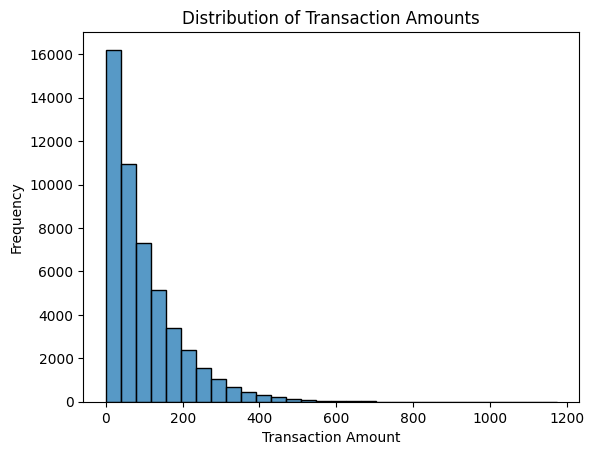

In [57]:

sns.histplot(data=df, x="Transaction_Amount", bins=30)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()


In [58]:

print("Mean:", round(df["Transaction_Amount"].mean(), 2))
print("Median:", round(df["Transaction_Amount"].median(), 2))
print("Minimum:", df["Transaction_Amount"].min())
print("Maximum:", df["Transaction_Amount"].max())


Mean: 99.31
Median: 69.61
Minimum: 0.0
Maximum: 1174.14


*Output Explanation*


Distribution: The transaction amounts are right-skewed, with the mean (99.31) higher than the median (69.61).



Majority range: 31,573 transactions (63.15%) have amounts below 100.



Range and extreme values: Transaction amounts range from 0 to 1,174.14, with relatively few transactions at the higher end.

**3. Risk Score Distribution by Fraud Label**

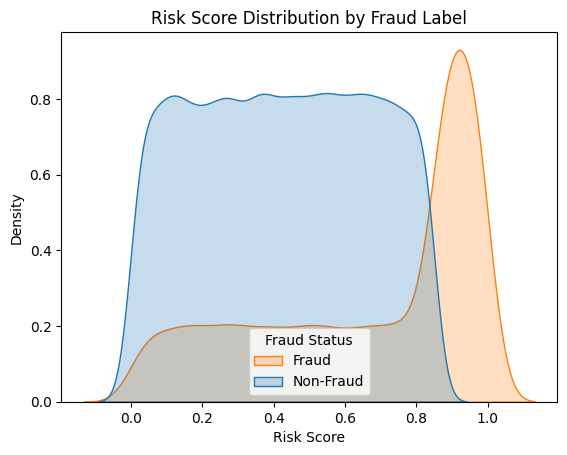

In [59]:


df["Fraud_Status"] = df["Fraud_Label"].map({
    0: "Non-Fraud",
    1: "Fraud"
})

sns.kdeplot(
    data=df,
    x="Risk_Score",
    hue="Fraud_Status",
    hue_order=["Non-Fraud", "Fraud"],
    fill=True
)

plt.title("Risk Score Distribution by Fraud Label")
plt.xlabel("Risk Score")
plt.ylabel("Density")
plt.legend(title="Fraud Status", labels=["Fraud", "Non-Fraud"])

plt.show()



*Output Explanation*

Non-Fraud distribution: Non-fraudulent transactions have a broader distribution of risk scores, extending across low and intermediate values.



Fraud distribution: Fraudulent transactions are concentrated towards higher risk scores, with a prominent peak around 0.92–0.95.



Key observation: Fraud-labelled transactions tend to have higher risk scores, although the distributions overlap. This indicates an association, not proof of causation.

**4. Failed Transaction Count by Fraud Status**

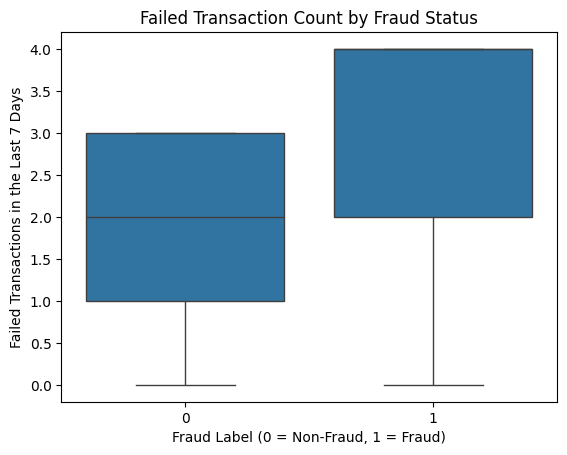

In [60]:

sns.boxplot(data=df, x="Fraud_Label", y="Failed_Transaction_Count_7d")

plt.title("Failed Transaction Count by Fraud Status")
plt.xlabel("Fraud Label (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Failed Transactions in the Last 7 Days")

plt.show()


Output Explanation


Median comparison: The median failed-transaction count is 2 for Non-Fraud and 4 for Fraud.



Distribution: The middle 50% ranges from 1–3 for Non-Fraud and 2–4 for Fraud.



Key observation: Fraud-labelled transactions tend to have higher recent failed-transaction counts, suggesting an association with the fraud label

**5. Account Balance by Fraud Status**

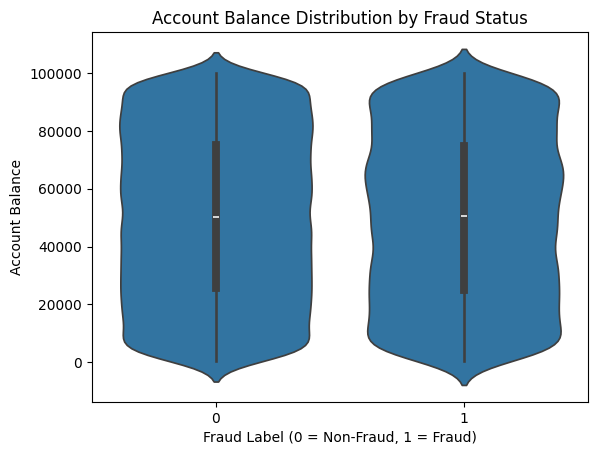

In [61]:

sns.violinplot(data=df, x="Fraud_Label", y="Account_Balance")

plt.title("Account Balance Distribution by Fraud Status")
plt.xlabel("Fraud Label (0 = Non-Fraud, 1 = Fraud)")
plt.ylabel("Account Balance")

plt.show()


***Output Explanation***

Mean comparison: The mean account balance is approximately 50,356.47 for Non-Fraud and 50,162.26 for Fraud.



Median comparison: The median is approximately 50,370.35 for Non-Fraud and 50,415.02 for Fraud.



Key observation: The mean and median values are similar across both groups, and the violin plots have broadly similar distributions. Therefore, account balance does not show a clear difference between the groups in this analysis.

**6. Fraud Rate by Location**

In [62]:

fraud_rate_location = df.groupby("Location")["Fraud_Label"].mean() * 100

print(fraud_rate_location)


Location
London      31.985923
Mumbai      31.578947
New York    32.486132
Sydney      32.139263
Tokyo       32.474530
Name: Fraud_Label, dtype: float64


In [63]:

fraud_rate_location = fraud_rate_location.reset_index()

fig = px.bar(
    fraud_rate_location,
    x="Location",
    y="Fraud_Label",
    title="Fraud Rate by Location",
    labels={
        "Location": "Location",
        "Fraud_Label": "Fraud Rate (%)"
    }
)

fig.show()


In [64]:

location_summary = df.groupby("Location").agg(
    Transaction_Count=("Fraud_Label", "count"),
    Fraud_Count=("Fraud_Label", "sum"),
    Fraud_Rate=("Fraud_Label", "mean")
).reset_index()

location_summary["Fraud_Rate"] = location_summary["Fraud_Rate"] * 100

print(location_summary.round(2))


   Location  Transaction_Count  Fraud_Count  Fraud_Rate
0    London               9945         3181       31.99
1    Mumbai               9994         3156       31.58
2  New York               9915         3221       32.49
3    Sydney               9938         3194       32.14
4     Tokyo              10208         3315       32.47


In [65]:

fig = px.bar(
    location_summary,
    x="Location",
    y="Fraud_Rate",
    text="Fraud_Rate",
    hover_data=["Transaction_Count", "Fraud_Count"],
    title="Fraud Rate by Location",
    labels={
        "Location": "Location",
        "Fraud_Rate": "Fraud Rate (%)",
        "Transaction_Count": "Total Transactions",
        "Fraud_Count": "Fraudulent Transactions"
    }
)

fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside"
)

fig.show()


*Output Explanation*

Highest and lowest rates: New York has the highest fraud rate at 32.49% (9,915 transactions), while Mumbai has the lowest at 31.58% (9,994 transactions).



Sample sizes: Each location contains approximately 9,900–10,200 transactions, making the group sizes relatively similar.



Key observation: Fraud rates range from 31.58% to 32.49%, indicating relatively little variation across locations in this dataset.

**7. Fraud Rate by Transaction Type**

In [82]:

type_summary = df.groupby("Transaction_Type").agg(
    Transaction_Count=("Fraud_Label", "count"),
    Fraud_Count=("Fraud_Label", "sum"),
    Fraud_Rate=("Fraud_Label", "mean")
).reset_index()

type_summary["Fraud_Rate"] = type_summary["Fraud_Rate"] * 100

print(type_summary.round(2))


  Transaction_Type  Transaction_Count  Fraud_Count  Fraud_Rate
0   ATM Withdrawal              12453         4046       32.49
1    Bank Transfer              12452         3995       32.08
2           Online              12546         4031       32.13
3              POS              12549         3995       31.84


In [83]:


fig = px.bar(
    type_summary,
    x="Transaction_Type",
    y="Fraud_Rate",
    text="Fraud_Rate",
    hover_data=["Transaction_Count", "Fraud_Count"],
    title="Fraud Rate by Transaction Type",
    labels={
        "Transaction_Type": "Transaction Type",
        "Fraud_Rate": "Fraud Rate (%)",
        "Transaction_Count": "Total Transactions",
        "Fraud_Count": "Fraudulent Transactions"
    }
)

fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside"
)

fig.show()


*Output Explanation*

Highest and lowest rates: ATM Withdrawal has the highest fraud rate at 32.49%, while POS has the lowest at 31.84%.



Sample sizes: Each transaction type contains approximately 12,450–12,550 transactions, so the group sizes are similar.



Key observation: Fraud rates vary only slightly across transaction types, suggesting no substantial difference in the observed rates in this dataset.

**8. Fraud Rate by Card Age Group**

In [69]:

df["Card_Age_Group"] = ""

for age in range(len(df)):
    if df.loc[age, "Card_Age"] <= 60:
        df.loc[age, "Card_Age_Group"] = "1-60 days"
    elif df.loc[age, "Card_Age"] <= 120:
        df.loc[age, "Card_Age_Group"] = "61-120 days"
    elif df.loc[age, "Card_Age"] <= 180:
        df.loc[age, "Card_Age_Group"] = "121-180 days"
    else:
        df.loc[age, "Card_Age_Group"] = "181-239 days"


In [70]:

fraud_rate_age = df.groupby("Card_Age_Group")["Fraud_Label"].mean() * 100

print(fraud_rate_age)


Card_Age_Group
1-60 days       32.150247
121-180 days    32.118705
181-239 days    31.834780
61-120 days     32.427045
Name: Fraud_Label, dtype: float64


In [72]:

fig = px.bar(
    fraud_rate_age,
    x="Card_Age_Group",
    y="Fraud_Label",
    title="Fraud Rate by Card Age Group",
    labels={
        "Card_Age_Group": "Card Age Group",
        "Fraud_Label": "Fraud Rate (%)"
    },
    category_orders={
        "Card_Age_Group": [
            "1-60 days",
            "61-120 days",
            "121-180 days",
            "181-239 days"
        ]
    }
)

fig.update_layout(width=800, height=500)
fig.show()


In [84]:

age_summary = df.groupby("Card_Age_Group").agg(
    Transaction_Count=("Fraud_Label", "count"),
    Fraud_Count=("Fraud_Label", "sum"),
    Fraud_Rate=("Fraud_Label", "mean")
).reset_index()

age_summary["Fraud_Rate"] = age_summary["Fraud_Rate"] * 100

print(age_summary.round(2))


  Card_Age_Group  Transaction_Count  Fraud_Count  Fraud_Rate
0      1-60 days              12566         4040       32.15
1   121-180 days              12569         4037       32.12
2   181-239 days              12323         3923       31.83
3    61-120 days              12542         4067       32.43


In [86]:

fig = px.bar(
    age_summary,
    x="Card_Age_Group",
    y="Fraud_Rate",
    text="Fraud_Rate",
    hover_data=["Transaction_Count", "Fraud_Count"],
    title="Fraud Rate by Card Age Group",
    labels={
        "Card_Age_Group": "Card Age Group",
        "Fraud_Rate": "Fraud Rate (%)",
        "Transaction_Count": "Total Transactions",
        "Fraud_Count": "Fraudulent Transactions"
    },
    category_orders={
        "Card_Age_Group": [
            "1-60 days",
            "61-120 days",
            "121-180 days",
            "181-239 days"
        ]
    }
)

fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside"
)

fig.update_layout(width=800, height=500)
fig.show()


*Output Explanation*

Highest and lowest rates: The 61–120-day group has the highest fraud rate at 32.43%, while the 181–239-day group has the lowest at 31.83%.



Sample sizes: Each group contains approximately 12,300–12,600 transactions, making the group sizes relatively similar.



Key observation: Fraud rates range from 31.83% to 32.43%, indicating little variation across card-age groups in this dataset.

**9. Fraud Rate by Risk Category**

In [73]:

df["Risk_Category"] = ""

for score in range(len(df)):
    if df.loc[score, "Risk_Score"] < 0.33:
        df.loc[score, "Risk_Category"] = "Low"
    elif df.loc[score, "Risk_Score"] < 0.66:
        df.loc[score, "Risk_Category"] = "Medium"
    else:
        df.loc[score, "Risk_Category"] = "High"


In [74]:

fraud_rate_risk = df.groupby("Risk_Category")["Fraud_Label"].mean() * 100

print(fraud_rate_risk)


Risk_Category
High      56.019988
Low       19.984091
Medium    19.655193
Name: Fraud_Label, dtype: float64


In [75]:

fraud_rate_risk = fraud_rate_risk.reset_index()

fig = px.bar(
    fraud_rate_risk,
    x="Risk_Category",
    y="Fraud_Label",
    title="Fraud Rate by Risk Category",
    labels={
        "Risk_Category": "Risk Category",
        "Fraud_Label": "Fraud Rate (%)"
    },
    category_orders={
        "Risk_Category": ["Low", "Medium", "High"]
    }
)

fig.show()


In [87]:

risk_summary = df.groupby("Risk_Category").agg(
    Transaction_Count=("Fraud_Label", "count"),
    Fraud_Count=("Fraud_Label", "sum"),
    Fraud_Rate=("Fraud_Label", "mean")
).reset_index()

risk_summary["Fraud_Rate"] = risk_summary["Fraud_Rate"] * 100

print(risk_summary.round(2))


  Risk_Category  Transaction_Count  Fraud_Count  Fraud_Rate
0          High              17010         9529       56.02
1           Low              16343         3266       19.98
2        Medium              16647         3272       19.66


In [88]:

fig = px.bar(
    risk_summary,
    x="Risk_Category",
    y="Fraud_Rate",
    text="Fraud_Rate",
    hover_data=["Transaction_Count", "Fraud_Count"],
    title="Fraud Rate by Risk Category",
    labels={
        "Risk_Category": "Risk Category",
        "Fraud_Rate": "Fraud Rate (%)",
        "Transaction_Count": "Total Transactions",
        "Fraud_Count": "Fraudulent Transactions"
    },
    category_orders={
        "Risk_Category": ["Low", "Medium", "High"]
    }
)

fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside"
)

fig.update_layout(width=800, height=500)
fig.show()


*Output Explanation*


Highest fraud rate: The High risk category has the highest fraud rate at 56.02%, compared with 19.98% for Low risk and 19.66% for Medium risk.



Sample sizes: High risk contains 17,010 transactions, Low risk 16,343, and Medium risk 16,647. These counts are available by hovering over the bars.



Key observation: The High risk category has a substantially higher fraud rate, while Low and Medium are similar. This is an association in the dataset, not proof that the risk category independently predicts fraud.







**10. Monthly Transaction Trend**

In [76]:

print("Earliest transaction:", df["Timestamp"].min())
print("Latest transaction:", df["Timestamp"].max())


Earliest transaction: 2023-01-01 00:01:00
Latest transaction: 2023-12-31 23:50:00


In [77]:

df["Month"] = df["Timestamp"].dt.month

print(df[["Timestamp", "Month"]].head())


            Timestamp  Month
0 2023-08-14 19:30:00      8
1 2023-06-07 04:01:00      6
2 2023-06-20 15:25:00      6
3 2023-12-07 00:31:00     12
4 2023-11-11 23:44:00     11


In [78]:

monthly_transactions = df["Month"].value_counts().sort_index()

print(monthly_transactions)


Month
1     4188
2     3903
3     4259
4     4106
5     4162
6     4160
7     4213
8     4384
9     4087
10    4164
11    4085
12    4289
Name: count, dtype: int64


In [79]:

monthly_transactions = monthly_transactions.reset_index()
monthly_transactions.columns = ["Month", "Transaction_Count"]

fig = px.line(
    monthly_transactions,
    x="Month",
    y="Transaction_Count",
    title="Monthly Transaction Trend",
    markers=True,
    labels={
        "Month": "Month (1 = January, 12 = December)",
        "Transaction_Count": "Number of Transactions"
    }
)

fig.show()


*Output Explanation*

The line chart illustrates the monthly transaction volume from January to December 2023. Transaction activity fluctuates throughout the year, with the highest volume occurring in August at approximately 4,385 transactions and the lowest in February at approximately 3,900 transactions. A noticeable increase is also observed in December compared with November. Overall, the chart indicates variations in monthly transaction activity rather than a consistent upward or downward trend. Since this visualization represents total transaction volume, it does not independently indicate changes in fraudulent activity.

**11.Transaction Amount vs. Risk Score**

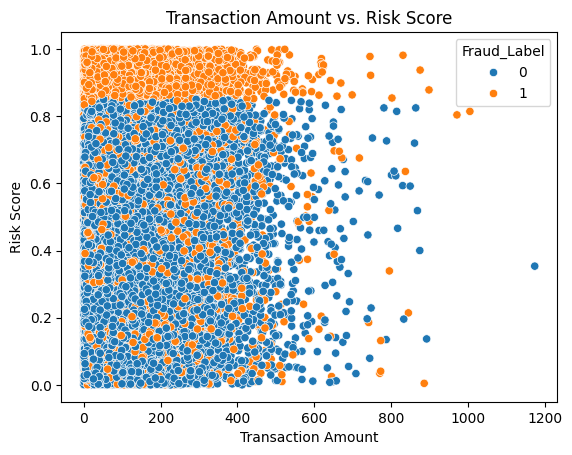

In [80]:

sns.scatterplot(
    data=df,
    x="Transaction_Amount",
    y="Risk_Score",
    hue="Fraud_Label"
)

plt.title("Transaction Amount vs. Risk Score")
plt.xlabel("Transaction Amount")
plt.ylabel("Risk Score")

plt.show()


*Output Explanation*

The scatterplot examines the relationship between transaction amount and risk score, with points differentiated by fraud label. Fraudulent transactions appear more concentrated towards the higher end of the risk-score range, while non-fraudulent transactions are distributed across a broader range of scores. Both categories occur across a wide range of transaction amounts, and no clear increasing relationship between transaction amount and risk score is apparent from the visualization. These observations suggest that risk score shows a more noticeable visual association with the fraud label than transaction amount. However, the chart does not establish causation or confirm the independent predictive value of the risk score.

**12. Correlation Heatmap**

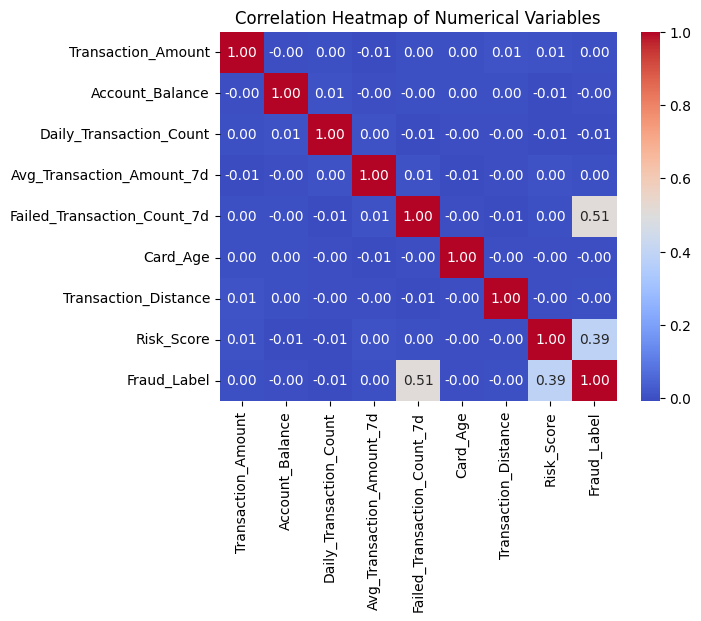

In [81]:

sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap of Numerical Variables")
plt.show()


*Output Explanation*

The correlation heatmap illustrates the direction and strength of linear relationships among the numerical variables and the fraud label. Failed transaction count over the previous seven days has the strongest positive correlation with Fraud_Label at approximately +0.51, followed by Risk_Score at +0.39. The remaining variables display correlations close to zero with the fraud label, indicating limited linear associations in this dataset. These results suggest that recent failed transaction activity and risk score are more strongly associated with the fraud label than the other numerical variables examined. However, correlation does not establish causation, and the construction of the risk score should be verified before interpreting its relationship with the fraud label as independent evidence.

**13. Fraud Rate by Authentication Method**

In [89]:

print(df["Authentication_Method"].value_counts())


Authentication_Method
Biometric    12591
PIN          12586
Password     12457
OTP          12366
Name: count, dtype: Int64


In [90]:

auth_summary = df.groupby("Authentication_Method").agg(
    Transaction_Count=("Fraud_Label", "count"),
    Fraud_Count=("Fraud_Label", "sum"),
    Fraud_Rate=("Fraud_Label", "mean")
).reset_index()

auth_summary["Fraud_Rate"] = auth_summary["Fraud_Rate"] * 100

print(auth_summary.round(2))


  Authentication_Method  Transaction_Count  Fraud_Count  Fraud_Rate
0             Biometric              12591         4038       32.07
1                   OTP              12366         4021       32.52
2                   PIN              12586         3978       31.61
3              Password              12457         4030       32.35


In [91]:

fig = px.bar(
    auth_summary,
    x="Authentication_Method",
    y="Fraud_Rate",
    text="Fraud_Rate",
    hover_data=["Transaction_Count", "Fraud_Count"],
    title="Fraud Rate by Authentication Method",
    labels={
        "Authentication_Method": "Authentication Method",
        "Fraud_Rate": "Fraud Rate (%)",
        "Transaction_Count": "Total Transactions",
        "Fraud_Count": "Fraudulent Transactions"
    }
)

fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside"
)

fig.show()


*Output Explanation*

Highest and lowest rates: OTP has the highest fraud rate at 32.52%, while PIN has the lowest at 31.61%.



Sample sizes: Each authentication method contains approximately 12,350–12,600 transactions, making the group sizes relatively similar.



Key observation: Fraud rates range from 31.61% to 32.52%, indicating relatively little variation across authentication methods in this dataset.

**14 Fraud Rate by Previous Fraudulent Activity**

In [92]:

print(df["Previous_Fraudulent_Activity"].value_counts())


Previous_Fraudulent_Activity
0    45080
1     4920
Name: count, dtype: int64


In [93]:

previous_fraud_summary = df.groupby("Previous_Fraudulent_Activity").agg(
    Transaction_Count=("Fraud_Label", "count"),
    Fraud_Count=("Fraud_Label", "sum"),
    Fraud_Rate=("Fraud_Label", "mean")
).reset_index()

previous_fraud_summary["Fraud_Rate"] = (
    previous_fraud_summary["Fraud_Rate"] * 100
)

previous_fraud_summary["Previous_Activity"] = (
    previous_fraud_summary["Previous_Fraudulent_Activity"].map({
        0: "No Previous Fraud",
        1: "Previous Fraud"
    })
)

print(previous_fraud_summary.round(2))


   Previous_Fraudulent_Activity  Transaction_Count  Fraud_Count  Fraud_Rate  \
0                             0              45080        14491       32.15   
1                             1               4920         1576       32.03   

   Previous_Activity  
0  No Previous Fraud  
1     Previous Fraud  


In [94]:

fig = px.bar(
    previous_fraud_summary,
    x="Previous_Activity",
    y="Fraud_Rate",
    text="Fraud_Rate",
    hover_data=["Transaction_Count", "Fraud_Count"],
    title="Fraud Rate by Previous Fraudulent Activity",
    labels={
        "Previous_Activity": "Previous Fraudulent Activity",
        "Fraud_Rate": "Fraud Rate (%)",
        "Transaction_Count": "Total Transactions",
        "Fraud_Count": "Fraudulent Transactions"
    }
)

fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside"
)

fig.show()


*Output Explanation*

Fraud rates: Transactions with no previous fraudulent activity have a fraud rate of 32.15%, compared with 32.03% for transactions with previously recorded fraudulent activity.



Sample sizes: The groups contain 45,080 transactions without previous fraudulent activity and 4,920 transactions with previous fraudulent activity.



Key observation: The difference is only 0.12 percentage points, indicating very similar fraud rates in this dataset. Previous fraudulent activity alone does not meaningfully distinguish the two groups based on these observed rates.

**15. Monthly Fraud Rate**

In [95]:

monthly_fraud = df.groupby("Month").agg(
    Transaction_Count=("Fraud_Label", "count"),
    Fraud_Count=("Fraud_Label", "sum"),
    Fraud_Rate=("Fraud_Label", "mean")
).reset_index()

monthly_fraud["Fraud_Rate"] = monthly_fraud["Fraud_Rate"] * 100

print(monthly_fraud.round(2))


    Month  Transaction_Count  Fraud_Count  Fraud_Rate
0       1               4188         1386       33.09
1       2               3903         1246       31.92
2       3               4259         1360       31.93
3       4               4106         1310       31.90
4       5               4162         1315       31.60
5       6               4160         1347       32.38
6       7               4213         1354       32.14
7       8               4384         1434       32.71
8       9               4087         1275       31.20
9      10               4164         1343       32.25
10     11               4085         1301       31.85
11     12               4289         1396       32.55


In [96]:

fig = px.line(
    monthly_fraud,
    x="Month",
    y="Fraud_Rate",
    markers=True,
    hover_data=["Transaction_Count", "Fraud_Count"],
    title="Monthly Fraud Rate Trend",
    labels={
        "Month": "Month (1 = January, 12 = December)",
        "Fraud_Rate": "Fraud Rate (%)",
        "Transaction_Count": "Total Transactions",
        "Fraud_Count": "Fraudulent Transactions"
    }
)

fig.update_traces(
    text=monthly_fraud["Fraud_Rate"].round(2),
    mode="lines+markers+text",
    texttemplate="%{text:.2f}%",
    textposition="top center"
)

fig.show()


*Output Explanation*

Highest and lowest rates: January recorded the highest fraud rate at 33.09%, while September recorded the lowest at 31.20%.



Monthly variation: The fraud rate ranged from 31.20% to 33.09%, a difference of 1.89 percentage points.



Key observation: Fraud rates fluctuated throughout 2023 without a consistent upward or downward trend. These results describe the proportion of transactions labelled as fraudulent each month, rather than the total number of fraudulent transactions.

**16. Fraud Rate By Card Type**

In [97]:

card_summary = df.groupby("Card_Type").agg(
    Transaction_Count=("Fraud_Label", "count"),
    Fraud_Count=("Fraud_Label", "sum"),
    Fraud_Rate=("Fraud_Label", "mean")
).reset_index()

card_summary["Fraud_Rate"] = card_summary["Fraud_Rate"] * 100

print(card_summary.round(2))


    Card_Type  Transaction_Count  Fraud_Count  Fraud_Rate
0        Amex              12415         4019       32.37
1    Discover              12320         4000       32.47
2  Mastercard              12681         4036       31.83
3     Unknown                 30           13       43.33
4        Visa              12554         3999       31.85


In [98]:

fig = px.bar(
    card_summary,
    x="Card_Type",
    y="Fraud_Rate",
    text="Fraud_Rate",
    hover_data=["Transaction_Count", "Fraud_Count"],
    title="Fraud Rate by Card Type",
    labels={
        "Card_Type": "Card Type",
        "Fraud_Rate": "Fraud Rate (%)",
        "Transaction_Count": "Total Transactions",
        "Fraud_Count": "Fraudulent Transactions"
    }
)

fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside"
)

fig.show()


*Output Explanation*

Highest and lowest rates: Unknown has the highest fraud rate at 43.33%, based on only 30 transactions. Among the four named card types, Discover is highest at 32.47%, while Mastercard is lowest at 31.83%.



Sample sizes: The four named card types each contain approximately 12,200–12,700 transactions, compared with just 30 for Unknown. Counts are available when hovering over the bars.



Key observation: Fraud rates across the four named card types are relatively similar, ranging from 31.83% to 32.47%. The higher rate for Unknown should be interpreted cautiously because its sample size is very small.

# Summary of Data Visualization Findings

### 1. What did we discover?

The analysis of 50,000 transactions identified 16,067 (32.13%) transactions labelled as fraudulent and 33,933 (67.87%) labelled as non-fraudulent. The visualizations revealed differences in risk scores and failed transaction counts between the two groups, while several other transaction characteristics showed relatively similar patterns.

### 2. What are the important patterns?

Fraud-labelled transactions were more concentrated at higher risk scores and generally had higher failed-transaction counts. Account balance distributions were broadly similar between fraud-labelled and non-fraudulent transactions. Fraud rates also showed limited variation across locations, transaction types, card-age groups, card types and authentication methods.

### 3. Which category had the highest observed fraud rate?

The High risk category had the highest observed fraud rate at approximately 56.02%, compared with 19.98% for Low risk and 19.66% for Medium risk. This indicates that a greater proportion of transactions in the High risk category were labelled as fraudulent. However, this result alone does not establish the predictive performance of the risk categories.

### 4. Which categories had lower observed fraud rates?

The Low and Medium risk categories recorded fraud rates of approximately 19.98% and 19.66%, respectively. Although these rates were lower than the High risk category, both groups still contained fraud-labelled transactions. Therefore, a Low or Medium risk classification did not guarantee that a transaction was non-fraudulent.

### 5. Were any unusual values observed?

Transaction amounts showed a right-skewed distribution, with a mean of approximately 99.31 and a median of 69.61. The maximum transaction amount was approximately 1,174.14, while 63.15% of transactions had amounts below 100. The higher transaction amounts may warrant further investigation, but they should not automatically be considered errors or fraudulent transactions.

The Card Type analysis also identified 30 records classified as `Unknown`. This category had an observed fraud rate of 43.33%, but the small sample size means the percentage should be interpreted cautiously.

### 6. What relationships were found?

The correlation heatmap showed a positive correlation of approximately +0.51 between failed transaction count over the previous seven days and the fraud label. Risk score had a positive correlation of approximately +0.39. Other numerical variables showed correlations close to zero with the fraud label. These results describe linear associations and do not establish causation.

### 7. What trends were observed?

Monthly transaction volumes fluctuated throughout 2023. August recorded the highest volume at approximately 4,384 transactions, while February recorded the lowest at approximately 3,903. The separate monthly fraud-rate chart showed that fraud rates ranged from 31.20% in September to 33.09% in January. Neither measure showed a consistent upward or downward trend throughout the year.

### 8. What can the business learn from the data?

The findings suggest that failed transaction activity may be a useful area for further fraud-risk investigation. Risk scores and risk categories may also help organize transactions for review, provided their methodology and effectiveness are validated. In contrast, the relatively similar fraud rates across locations, transaction types, card-age groups, card types and authentication methods indicate limited differentiation between these categories in the observed data.

Before applying these findings to a real banking fraud-detection process, the business should validate the risk-score methodology, investigate unusual records, and assess fraud-detection performance using appropriate evaluation measures. The findings represent patterns within this dataset and should not automatically be generalized to all banking transactions.